# 🌱 FarmerBud · Training the 4 neural networks
Yield, irrigation water, nitrogen and stability. At the end the networks are saved in `models.json`, the file used by the FarmerBud webapp.

## 0. Libraries

In [1]:
import copy
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.metrics import mean_absolute_error
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

## 1. Read the data

In [2]:
REPO = "byterunnersAI/FarmerBud"


def data_file(name):
    for folder in ["data", "../data"]:
        if os.path.exists(f"{folder}/{name}"):
            return f"{folder}/{name}"
    if not os.path.exists(name):
        answer = requests.get(f"https://raw.githubusercontent.com/{REPO}/main/data/{name}", timeout=120)
        answer.raise_for_status()
        with open(name, "wb") as file:
            file.write(answer.content)
    return name


yield_data = pd.read_csv(data_file("dataset_modello.csv"))
water_data = pd.read_csv(data_file("acqua_anni.csv"))
nitrogen_data = pd.read_csv(data_file("azoto_anni.csv"))
crops = pd.read_csv(data_file("colture.csv"))
provinces = pd.read_csv(data_file("punti_province.csv"))
print("Yield:", len(yield_data), "· Water:", len(water_data), "· Nitrogen:", len(nitrogen_data))

Yield: 4967 · Water: 6600 · Nitrogen: 4967


## 2. Two functions used by all 4 networks

In [3]:
def train_network(X_train, y_train, X_val, y_val, hidden, alpha, epochs, unit, batch=64, verbose=True):
    net = MLPRegressor(
        hidden_layer_sizes=hidden,
        activation="relu",
        learning_rate_init=0.001,
        alpha=alpha,
        batch_size=batch,
        random_state=42,
    )
    err_train, err_val = [], []
    best_err, best_epoch, best_net = float("inf"), 0, None
    for epoch in range(1, epochs + 1):
        net.partial_fit(X_train, y_train)
        err_train.append(mean_absolute_error(y_train, net.predict(X_train)) * unit)
        err_val.append(mean_absolute_error(y_val, net.predict(X_val)) * unit)
        if err_val[-1] < best_err:
            best_err, best_epoch, best_net = err_val[-1], epoch, copy.deepcopy(net)
    if verbose:
        print(f"Best: epoch {best_epoch}, validation error {best_err:.2f}")
    return best_net, net.loss_curve_, err_train, err_val, best_epoch


def plot_training(title, loss, err_train, err_val, best_epoch, unit_label):
    epochs = range(1, len(loss) + 1)
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
    left.plot(epochs, loss, color="tab:blue")
    left.set_title(f"{title}: loss during training")
    left.set_xlabel("Epoch")
    left.set_ylabel("Loss")
    right.plot(epochs, err_train, label="Train", color="tab:blue")
    right.plot(epochs, err_val, label="Validation", color="tab:orange")
    right.axvline(best_epoch, color="gray", linestyle="--", label=f"Best network ({best_epoch})")
    right.set_title(f"{title}: mean error")
    right.set_xlabel("Epoch")
    right.set_ylabel(unit_label)
    right.legend()
    plt.tight_layout()
    plt.show()


models = {}

## 3. Network 1: yield

Best: epoch 138, validation error 12.78


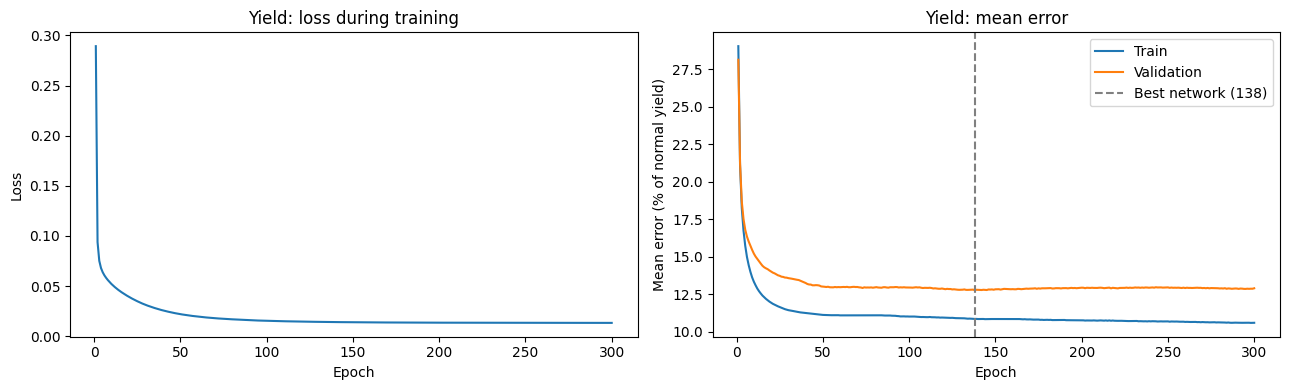

In [4]:
not_inputs = ["cod_provincia", "anno", "periodo", "resa_relativa"]
X = pd.get_dummies(yield_data.drop(columns=not_inputs), columns=["cod_coltura"], dtype=float)
y = yield_data["resa_relativa"]
train = yield_data["anno"] <= 2018
val = yield_data["anno"].between(2019, 2021)
test = yield_data["anno"] >= 2022
scaler = StandardScaler().fit(X[train])
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.1, epochs=300, unit=100)
plot_training("Yield", loss, err_train, err_val, best, "Mean error (% of normal yield)")

In [5]:
prediction = net.predict(scaler.transform(X[test]))
naive = yield_data.loc[test, "cod_coltura"].map(yield_data[train | val].groupby("cod_coltura")["resa_relativa"].mean())
print(f"Network error: {mean_absolute_error(y[test], prediction) * 100:.1f}%")
print(f"Naive prediction error: {mean_absolute_error(y[test], naive) * 100:.1f}%")
year_2022 = yield_data.loc[test, ["anno", "cod_coltura"]].assign(true=y[test], network=prediction, naive=naive)
print(year_2022[year_2022["anno"] == 2022].groupby("cod_coltura")[["true", "network", "naive"]].mean().round(2))
models["yield"] = {"net": net, "scaler": scaler, "columns": list(X.columns), "out_scale": 1}

Network error: 14.4%
Naive prediction error: 15.0%
             true  network  naive
cod_coltura                      
BARLEY       1.10     1.03   1.00
BEETS        0.77     0.92   0.99
COMMEAT      1.02     1.06   1.01
MAIZE        0.81     0.89   0.99
RAPE         1.00     1.01   0.95
RICE         0.87     1.00   1.01
SORGH        0.87     0.92   0.98
SOYA         0.85     0.93   0.99
SUNFLO       0.96     0.89   0.98
WHEATD       1.01     1.07   0.97


### 3b. The hardest test: provinces never seen

In [6]:
left_out = yield_data[["cod_provincia", "cod_coltura", "anno", "resa_relativa"]].copy()
left_out["network"], left_out["naive"] = 0.0, 0.0
X = pd.get_dummies(yield_data.drop(columns=not_inputs), columns=["cod_coltura"], dtype=float)
y = yield_data["resa_relativa"]
for province in yield_data["cod_provincia"].unique():
    out = yield_data["cod_provincia"] == province
    val = ~out & yield_data["anno"].between(2019, 2021)
    train = ~out & ~val
    scaler_lo = StandardScaler().fit(X[train])
    net_lo = train_network(scaler_lo.transform(X[train]), y[train], scaler_lo.transform(X[val]), y[val],
                           hidden=(32, 16), alpha=0.1, epochs=150, unit=100, verbose=False)[0]
    left_out.loc[out, "network"] = net_lo.predict(scaler_lo.transform(X[out]))
    left_out.loc[out, "naive"] = left_out.loc[out, "cod_coltura"].map(yield_data[~out].groupby("cod_coltura")["resa_relativa"].mean())
print(f"Network error: {mean_absolute_error(left_out['resa_relativa'], left_out['network']) * 100:.1f}%")
print(f"Naive prediction error: {mean_absolute_error(left_out['resa_relativa'], left_out['naive']) * 100:.1f}%")

Network error: 15.3%
Naive prediction error: 15.1%


In [7]:
averages = left_out.groupby(["cod_provincia", "cod_coltura"])[["resa_relativa", "network", "naive"]].mean()
hits = []
for province, here in averages.groupby(level="cod_provincia"):
    if len(here) < 5:
        continue
    true_top3 = set(here["resa_relativa"].nlargest(3).index)
    hits.append({"network": len(true_top3 & set(here["network"].nlargest(3).index)) / 3,
                 "naive rule": len(true_top3 & set(here["naive"].nlargest(3).index)) / 3,
                 "chance": 3 / len(here)})
print("Top crops guessed right (out of 3), on average, %")
print((pd.DataFrame(hits).mean() * 100).round(0))

Top crops guessed right (out of 3), on average, %
network       49.0
naive rule    41.0
chance        35.0
dtype: float64


In [8]:
left_out = left_out.merge(provinces[["cod_provincia", "provincia", "regione"]], on="cod_provincia")
left_out["network_error"] = (left_out["network"] - left_out["resa_relativa"]).abs() * 100
left_out["naive_error"] = (left_out["naive"] - left_out["resa_relativa"]).abs() * 100
print(left_out.groupby("regione")[["network_error", "naive_error"]].mean().round(1))
print(left_out.nlargest(5, "network_error")[["provincia", "anno", "cod_coltura", "resa_relativa", "network", "naive"]].round(2))

                network_error  naive_error
regione                                   
Emilia-Romagna           14.7         14.5
Lombardia                15.4         15.1
Piemonte                 17.8         18.0
Veneto                   13.5         13.3
    provincia  anno cod_coltura  resa_relativa  network  naive
392    Biella  2012       MAIZE           1.60     0.78   0.99
210    Torino  2025        SOYA           1.51     0.74   1.00
432    Biella  2010        SOYA           1.43     0.67   1.00
343  Vercelli  2011      SUNFLO           0.32     1.06   0.99
342  Vercelli  2010      SUNFLO           0.32     1.05   0.99


## 4. Network 2: irrigation water

Best: epoch 11, validation error 28.37


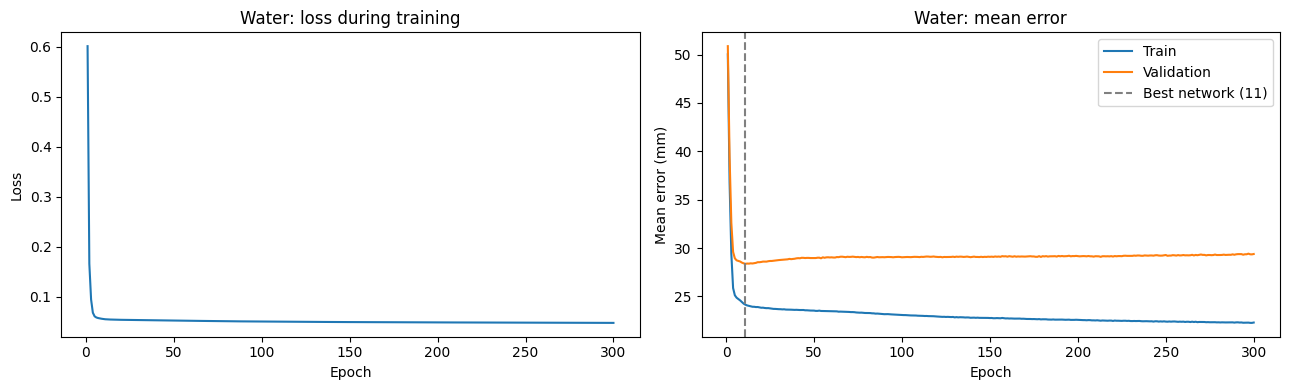

Network error: 30.9 mm
Naive prediction error: 73.4 mm


In [9]:
X = pd.get_dummies(water_data[["et0_ciclo_mm", "pioggia_ciclo_mm", "cod_coltura"]], columns=["cod_coltura"], dtype=float)
y = water_data["irrigazione_mm"] / 100
train = water_data["anno"] <= 2018
val = water_data["anno"].between(2019, 2021)
test = water_data["anno"] >= 2022
scaler = StandardScaler().fit(X[train])
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.0001, epochs=300, unit=100)
plot_training("Water", loss, err_train, err_val, best, "Mean error (mm)")
prediction = (net.predict(scaler.transform(X[test])) * 100).clip(min=0)
naive = water_data.loc[test, "cod_coltura"].map(water_data[train | val].groupby("cod_coltura")["irrigazione_mm"].mean())
print(f"Network error: {mean_absolute_error(y[test] * 100, prediction):.1f} mm")
print(f"Naive prediction error: {mean_absolute_error(y[test] * 100, naive):.1f} mm")
models["water"] = {"net": net, "scaler": scaler, "columns": list(X.columns), "out_scale": 100}

## 5. Network 3: nitrogen

Best: epoch 498, validation error 6.39


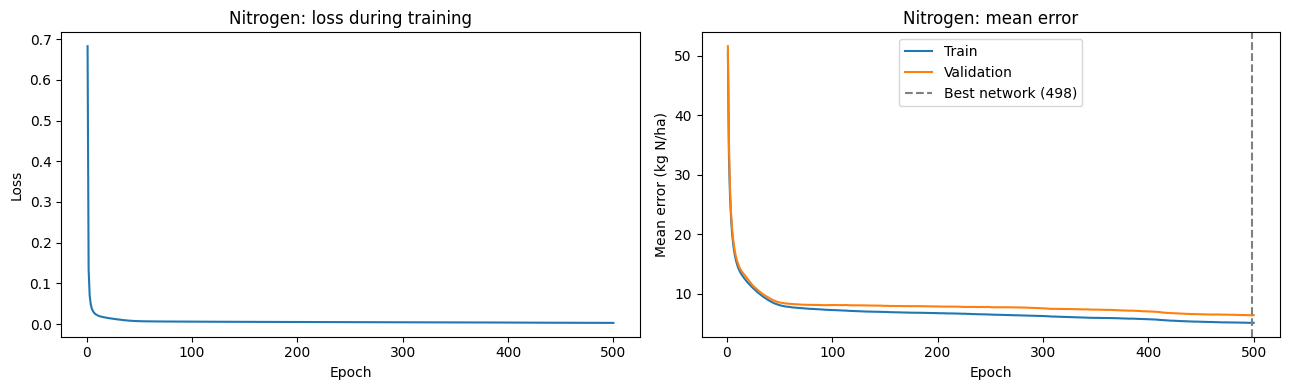

Network error: 6.9 kg/ha
Naive prediction error: 16.1 kg/ha


In [10]:
nitrogen_inputs = ["resa_t_ha", "pioggia_ott_feb_mm", "sostanza_organica"]
text_inputs = ["coltura_precedente", "cod_coltura"]
X = pd.get_dummies(nitrogen_data[nitrogen_inputs + text_inputs], columns=text_inputs, dtype=float)
y = nitrogen_data["azoto_kg_ha"] / 100
train = nitrogen_data["anno"] <= 2018
val = nitrogen_data["anno"].between(2019, 2021)
test = nitrogen_data["anno"] >= 2022
scaler = StandardScaler().fit(X[train])
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.0001, epochs=500, unit=100)
plot_training("Nitrogen", loss, err_train, err_val, best, "Mean error (kg N/ha)")
prediction = (net.predict(scaler.transform(X[test])) * 100).clip(min=0)
naive = nitrogen_data.loc[test, "cod_coltura"].map(nitrogen_data[train | val].groupby("cod_coltura")["azoto_kg_ha"].mean())
print(f"Network error: {mean_absolute_error(y[test] * 100, prediction):.1f} kg/ha")
print(f"Naive prediction error: {mean_absolute_error(y[test] * 100, naive):.1f} kg/ha")
models["nitrogen"] = {"net": net, "scaler": scaler, "columns": list(X.columns), "out_scale": 100}

In [11]:
example = pd.DataFrame({"resa_t_ha": 8.0, "pioggia_ott_feb_mm": 250.0, "sostanza_organica": 0,
                        "coltura_precedente": ["NONE", "COMMEAT", "MAIZE", "SOYA", "BEETS"], "cod_coltura": "MAIZE"})
example_X = pd.get_dummies(example, columns=text_inputs, dtype=float).reindex(columns=X.columns, fill_value=0.0)
example["nitrogen_kg_ha"] = (net.predict(scaler.transform(example_X)) * 100).round(0)
print(example[["coltura_precedente", "nitrogen_kg_ha"]].to_string(index=False))

coltura_precedente  nitrogen_kg_ha
              NONE           146.0
           COMMEAT           180.0
             MAIZE           187.0
              SOYA           150.0
             BEETS           144.0


## 6. Network 4: stability over the years

255 rows (province × crop)


Best: epoch 257, validation error 3.35


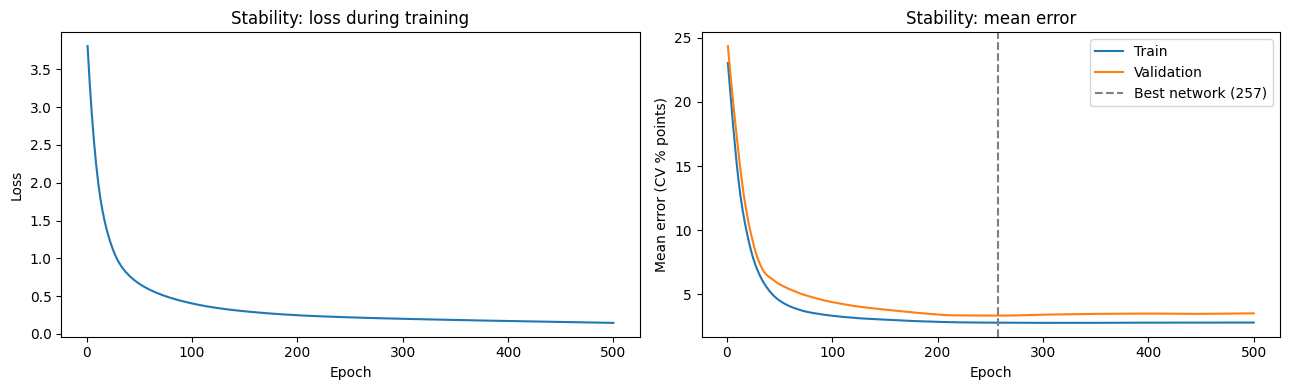

Network error: 3.8 CV points
Naive prediction error: 4.5 CV points


In [12]:
climate = ["temp_media", "temp_max_media", "temp_min_media", "pioggia_mm", "et0_mm", "bilancio_idrico_mm",
           "radiazione_MJ_m2", "umidita_media", "vento_medio_m_s", "gradi_giorno", "giorni_sopra_35",
           "giorni_gelo", "periodo_secco_max_giorni"]
climate_spread = ["bilancio_idrico_mm", "pioggia_mm", "temp_max_media", "giorni_sopra_35", "periodo_secco_max_giorni"]
place = ["ph", "argilla_pct", "sabbia_pct", "limo_pct", "carbonio_organico_g_kg", "azoto_g_kg", "lat", "lon", "quota_m"]
groups = yield_data.groupby(["cod_provincia", "cod_coltura"])
stability_data = (groups[climate].mean()
                  .join(groups[climate_spread].std().add_suffix("_std"))
                  .join(groups[place].first())
                  .join(groups.size().rename("years")))
stability_data["cv_pct"] = groups["resa_relativa"].std() / groups["resa_relativa"].mean() * 100
stability_data = stability_data[stability_data["years"] >= 10].reset_index()
print(len(stability_data), "rows (province × crop)")
province_list = sorted(stability_data["cod_provincia"].unique())
np.random.default_rng(0).shuffle(province_list)
test = stability_data["cod_provincia"].isin(province_list[:7])
val = stability_data["cod_provincia"].isin(province_list[7:13])
train = ~test & ~val
X = pd.get_dummies(stability_data.drop(columns=["cod_provincia", "years", "cv_pct"]), columns=["cod_coltura"], dtype=float)
y = stability_data["cv_pct"] / 10
scaler = StandardScaler().fit(X[train])
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(8,), alpha=3, epochs=500, unit=10, batch=32)
plot_training("Stability", loss, err_train, err_val, best, "Mean error (CV % points)")
prediction = net.predict(scaler.transform(X[test])) * 10
naive = stability_data.loc[test, "cod_coltura"].map(stability_data[train | val].groupby("cod_coltura")["cv_pct"].median())
print(f"Network error: {mean_absolute_error(y[test] * 10, prediction):.1f} CV points")
print(f"Naive prediction error: {mean_absolute_error(y[test] * 10, naive):.1f} CV points")
models["stability"] = {"net": net, "scaler": scaler, "columns": list(X.columns), "out_scale": 10}

## 7. Save the 4 networks for the webapp

In [13]:
def round6(values):
    return np.vectorize(lambda v: float(f"{v:.6g}"))(values).tolist()


def network_to_dict(m):
    return {
        "columns": m["columns"],
        "mean": round6(m["scaler"].mean_),
        "scale": round6(m["scaler"].scale_),
        "weights": [round6(w) for w in m["net"].coefs_],
        "biases": [round6(b) for b in m["net"].intercepts_],
        "out_scale": m["out_scale"],
    }


export = {name: network_to_dict(models[name]) for name in ["yield", "water", "nitrogen", "stability"]}
export["stability"]["climate"] = climate
export["stability"]["climate_spread"] = climate_spread
export["crop_median_t_ha"] = dict(zip(crops["cod_coltura"], crops["resa_mediana_padana_2006_2021_t_ha"]))
points = yield_data.groupby("cod_provincia")[place].first().reset_index()
points = points.merge(provinces[["cod_provincia", "provincia", "comune_punto"]], on="cod_provincia")
export["points"] = points.round(4).to_dict(orient="records")
with open("models.json", "w") as file:
    json.dump(export, file)
print(f"Saved models.json ({os.path.getsize('models.json') / 1024:.0f} KB)")

Saved models.json (60 KB)


## 8. Check: the webapp formula gives the same numbers

In [14]:
def predict_like_webapp(m, X):
    h = (X - np.array(m["mean"])) / np.array(m["scale"])
    for i, (w, b) in enumerate(zip(m["weights"], m["biases"])):
        h = h @ np.array(w) + np.array(b)
        if i < len(m["weights"]) - 1:
            h = np.maximum(h, 0)
    return h[:, 0] * m["out_scale"]


inputs = {"yield": pd.get_dummies(yield_data.drop(columns=not_inputs), columns=["cod_coltura"], dtype=float),
          "water": pd.get_dummies(water_data[["et0_ciclo_mm", "pioggia_ciclo_mm", "cod_coltura"]], columns=["cod_coltura"], dtype=float),
          "nitrogen": pd.get_dummies(nitrogen_data[nitrogen_inputs + text_inputs], columns=text_inputs, dtype=float),
          "stability": pd.get_dummies(stability_data.drop(columns=["cod_provincia", "years", "cv_pct"]), columns=["cod_coltura"], dtype=float)}
for name, X_all in inputs.items():
    X_all = X_all[models[name]["columns"]]
    sklearn_prediction = models[name]["net"].predict(models[name]["scaler"].transform(X_all)) * models[name]["out_scale"]
    webapp_prediction = predict_like_webapp(export[name], X_all.values)
    print(f"{name}: max difference {np.abs(sklearn_prediction - webapp_prediction).max():.6f}")

yield: max difference 0.000014
water: max difference 0.000576
nitrogen: max difference 0.000837
stability: max difference 0.000180
